Ali Khabazian - 402416066 // Complex system project - all codes

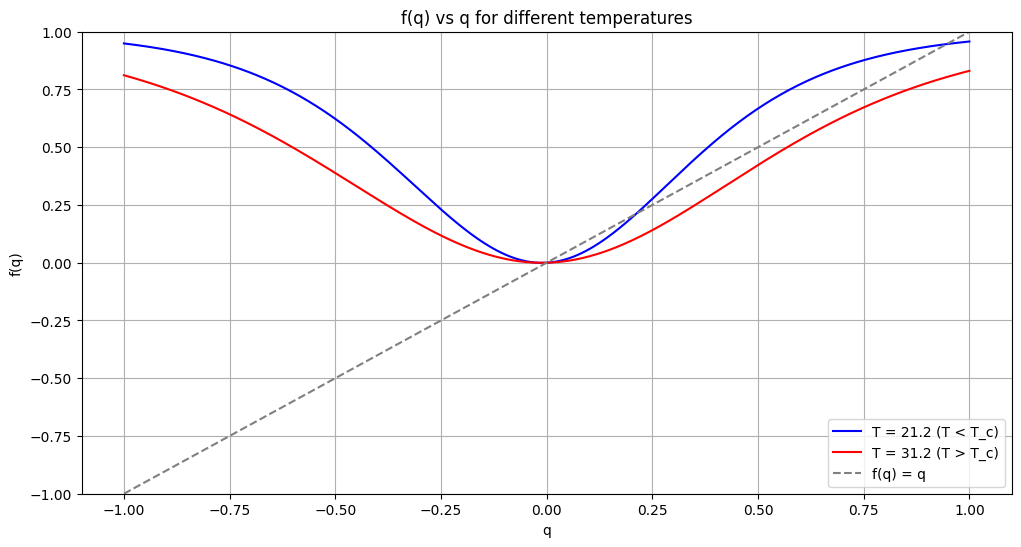

In [1]:
import numpy as np
import matplotlib.pyplot as plt


N = 50
T_c = 26.2
q_range = np.linspace(-1, 1, 400)

def beta(T):
    return 1 / T

def p(q, beta, N):
    return np.tanh(beta * (N - 2) * q)

def f_q(q, beta, N):
    p_val = p(q, beta, N)
    numerator = (np.exp(-beta * (N - 3) * (-2 * q)) - 2 * np.exp(-beta * 2 * p_val) + np.exp(-beta * (N - 3) * 2 * q))
    denominator = (np.exp(-beta * (N - 3) * (-2 * q)) + 2 * np.exp(-beta * 2 * p_val) + np.exp(-beta * (N - 3) * 2 * q))
    return numerator / denominator

# Temperature values
T_low = T_c - 5  # T < T_c
T_high = T_c + 5  # T > T_c


beta_low = beta(T_low)
beta_high = beta(T_high)

f_q_low = [f_q(q, beta_low, N) for q in q_range]
f_q_high = [f_q(q, beta_high, N) for q in q_range]


plt.figure(figsize=(12, 6))

plt.plot(q_range, f_q_low, label=f'T = {T_low} (T < T_c)', color='blue')
plt.plot(q_range, f_q_high, label=f'T = {T_high} (T > T_c)', color='red')

plt.plot(q_range, q_range, linestyle='--', color='gray', label='f(q) = q')

plt.xlabel('q')
plt.ylabel('f(q)')
plt.title('f(q) vs q for different temperatures')
plt.legend()
plt.grid(True)
plt.ylim(-1, 1)
plt.show()


C:\Users\user\AppData\Local\Temp\ipykernel_1248\4227008370.py:6: RuntimeWarning: divide by zero encountered in double_scalars
  beta = 1/T
C:\Users\user\AppData\Local\Temp\ipykernel_1248\4227008370.py:7: RuntimeWarning: invalid value encountered in double_scalars
  p = np.tanh(beta*(n-2)*q)
C:\Users\user\AppData\Local\Temp\ipykernel_1248\4227008370.py:8: RuntimeWarning: invalid value encountered in double_scalars
  return (np.exp(-beta*(n-3)*(-2*q)) - 2*np.exp(-beta*(2*p)) + np.exp(-beta*(n-3)*(2*q))) / (np.exp(-beta*(n-3)*(-2*q)) + 2*np.exp(-beta*(2*p)) + np.exp(-beta*(n-3)*(2*q)))
C:\Users\user\AppData\Local\Temp\ipykernel_1248\4227008370.py:8: RuntimeWarning: overflow encountered in exp
  return (np.exp(-beta*(n-3)*(-2*q)) - 2*np.exp(-beta*(2*p)) + np.exp(-beta*(n-3)*(2*q))) / (np.exp(-beta*(n-3)*(-2*q)) + 2*np.exp(-beta*(2*p)) + np.exp(-beta*(n-3)*(2*q)))


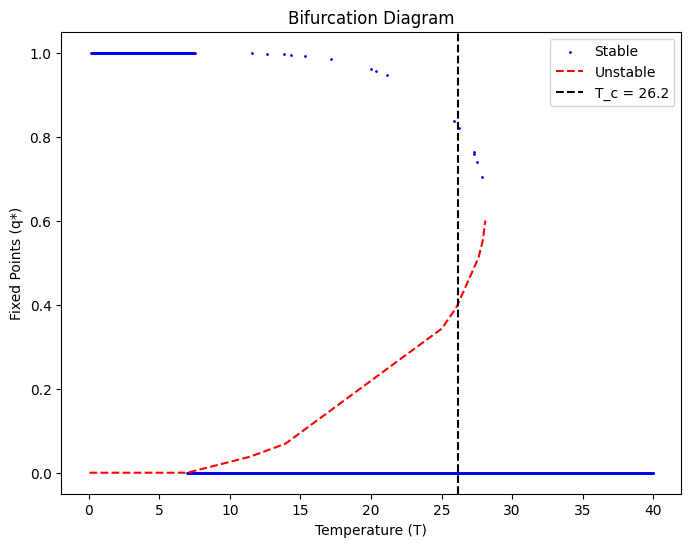

In [3]:
import numpy as np
import matplotlib.pyplot as plt


def f(q, T, n=50):
    beta = 1/T
    p = np.tanh(beta*(n-2)*q)
    return (np.exp(-beta*(n-3)*(-2*q)) - 2*np.exp(-beta*(2*p)) + np.exp(-beta*(n-3)*(2*q))) / (np.exp(-beta*(n-3)*(-2*q)) + 2*np.exp(-beta*(2*p)) + np.exp(-beta*(n-3)*(2*q)))


T_range = np.linspace(0, 40, 1000)
T_c = 26.2


q_star = []
for T in T_range:
    q_vals = np.linspace(0, 1, 1000)
    fixed_points = [q for q in q_vals if np.isclose(q, f(q, T), atol=1e-6)]
    q_star.append(fixed_points)


stable_states = []
unstable_states = []
for T, fixed_points in zip(T_range, q_star):
    for q in fixed_points:
        df_dq = (f(q + 1e-6, T) - f(q - 1e-6, T)) / (2e-6)
        if abs(df_dq) < 1:
            stable_states.append((T, q))
        else:
            unstable_states.append((T, q))


plt.figure(figsize=(8, 6))
stable_Ts, stable_qs = zip(*stable_states)
unstable_Ts, unstable_qs = zip(*unstable_states)
plt.scatter(stable_Ts, stable_qs, s=1, c='b', label='Stable')
plt.plot(unstable_Ts, unstable_qs, 'r--', label='Unstable')
plt.axvline(x=T_c, color='k', linestyle='--', label=f'T_c = {T_c}')
plt.xlabel('Temperature (T)')
plt.ylabel('Fixed Points (q*)')
plt.title('Bifurcation Diagram')
plt.legend()
plt.show()

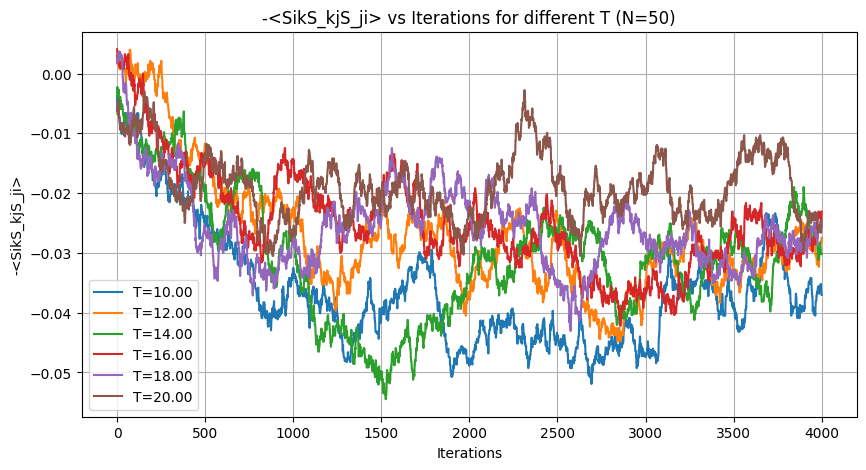

In [8]:
import numpy as np
import matplotlib.pyplot as plt


def initialize_network(N):
    edges = np.random.choice([-1, 1], size=(N, N))
    np.fill_diagonal(edges, 0)  
    return edges


def calculate_energy(edges):
    N = len(edges)
    energy = 0
    for i in range(N):
        for j in range(i + 1, N):
            for k in range(j + 1, N):
                energy -= edges[i, j] * edges[j, k] * edges[k, i]
    return energy


def monte_carlo_step(edges, T):
    N = len(edges)
    i, j = np.random.randint(0, N, size=2)
    if i == j:
        return 0
    edges[i, j] *= -1
    edges[j, i] *= -1
    delta_E = -2 * sum(edges[i, k] * edges[k, j] * edges[j, i] for k in range(N) if k != i and k != j)
    if delta_E < 0 or np.random.rand() < np.exp(-delta_E / T):
        return delta_E
    edges[i, j] *= -1
    edges[j, i] *= -1
    return 0


def calculate_SikS_kjS_ji_from_network(edges):
    N = len(edges)
    sum_triplets = 0
    count_triplets = 0
    for i in range(N):
        for j in range(i + 1, N):
            for k in range(j + 1, N):
                sum_triplets += edges[i, j] * edges[j, k] * edges[k, i]
                count_triplets += 1
    return -sum_triplets / count_triplets if count_triplets > 0 else 0


def simulate_network_evolution(N, T, num_iterations):
    edges = initialize_network(N)
    SikS_kjS_ji_values = []

    for _ in range(num_iterations):
        monte_carlo_step(edges, T)
        SikS_kjS_ji = calculate_SikS_kjS_ji_from_network(edges)
        SikS_kjS_ji_values.append(SikS_kjS_ji)

    return SikS_kjS_ji_values


def plot_SikS_kjS_ji_vs_iterations(T_values, N, num_iterations):
    plt.figure(figsize=(10, 5))

    for T in T_values:
        SikS_kjS_ji_values = simulate_network_evolution(N, T, num_iterations)
        plt.plot(range(num_iterations), SikS_kjS_ji_values, label=f'T={T:.2f}')

    plt.xlabel('Iterations')
    plt.ylabel('-<SikS_kjS_ji>')
    plt.title(f'-<SikS_kjS_ji> vs Iterations for different T (N={N})')
    plt.legend()
    plt.grid(True)
    plt.show()


N = 50  
T_values = [10,12,14,16,18,20]  
num_iterations = 4000  


plot_SikS_kjS_ji_vs_iterations(T_values, N, num_iterations)


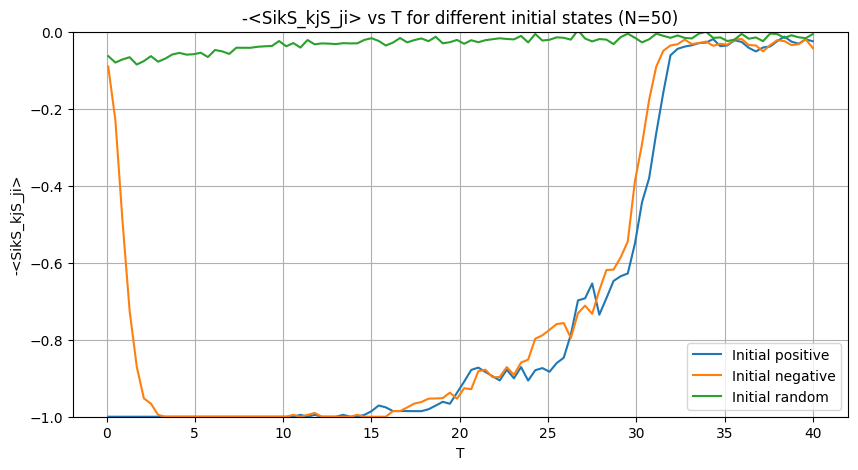

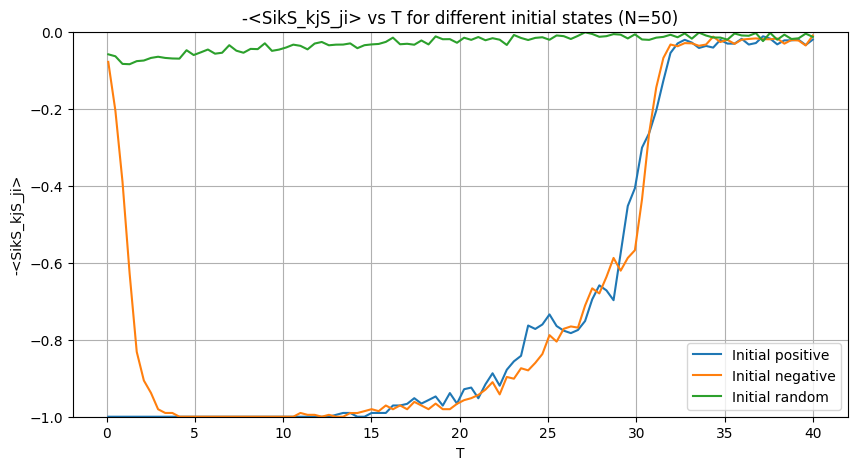

In [5]:
import numpy as np
import matplotlib.pyplot as plt


def calculate_SikS_kjS_ji(N, T, q=1):
    beta = 1 / T
    numerator = (
        np.exp(beta * (N - 3) * (3 * q) + beta) -
        3 * np.exp(beta * (N - 3) * (q) - beta) +
        3 * np.exp(beta * (N - 3) * (-q) + beta) -
        np.exp(beta * (N - 3) * (-3 * q) - beta)
    )
    
    denominator = (
        np.exp(beta * (N - 3) * (3 * q) + beta) +
        3 * np.exp(beta * (N - 3) * (q) - beta) +
        3 * np.exp(beta * (N - 3) * (-q) + beta) +
        np.exp(beta * (N - 3) * (-3 * q) - beta)
    )
    
    SikS_kjS_ji = - numerator / denominator
    return SikS_kjS_ji


def calculate_SikS_kjS_ji_from_network(edges):
    N = len(edges)
    sum_triplets = 0
    count_triplets = 0
    for i in range(N):
        for j in range(i + 1, N):
            for k in range(j + 1, N):
                sum_triplets += edges[i, j] * edges[j, k] * edges[k, i]
                count_triplets += 1
    return -sum_triplets / count_triplets if count_triplets > 0 else 0


def initialize_network(N, init_type='random'):
    if init_type == 'positive':
        edges = np.ones((N, N))
    elif init_type == 'negative':
        edges = -np.ones((N, N))
    elif init_type == 'random':
        edges = np.random.choice([-1, 1], size=(N, N))
    np.fill_diagonal(edges, 0)  
    return edges


def monte_carlo_step(edges, T):
    N = len(edges)
    i, j = np.random.randint(0, N, size=2)
    if i == j:
        return 0
    edges[i, j] *= -1
    edges[j, i] *= -1
    delta_E = -2 * sum(edges[i, k] * edges[k, j] * edges[j, i] for k in range(N) if k != i and k != j)
    if delta_E < 0 or np.random.rand() < np.exp(-delta_E / T):
        return delta_E
    edges[i, j] *= -1
    edges[j, i] *= -1
    return 0


def simulate_network_evolution(N, T_values, init_type):
    edges = initialize_network(N, init_type)
    SikS_kjS_ji_values = []

    for T in T_values:
        for _ in range(1000):  
            monte_carlo_step(edges, T)
        SikS_kjS_ji = calculate_SikS_kjS_ji_from_network(edges)
        SikS_kjS_ji_values.append(SikS_kjS_ji)

    return SikS_kjS_ji_values


def plot_SikS_kjS_ji_vs_T(T_values, N):
    init_types = ['positive', 'negative', 'random']
    plt.figure(figsize=(10, 5))

    for init_type in init_types:
        SikS_kjS_ji_values = simulate_network_evolution(N, T_values, init_type)
        plt.plot(T_values, SikS_kjS_ji_values, label=f'Initial {init_type}')

    plt.xlabel('T')
    plt.ylabel('-<SikS_kjS_ji>')
    plt.title(f'-<SikS_kjS_ji> vs T for different initial states (N={N})')
    plt.ylim(-1, 0)
    plt.legend()
    plt.grid(True)
    plt.show()


N = 50 
T_values = np.linspace(0.1, 40, 100)  

plot_SikS_kjS_ji_vs_T(T_values, N)
import numpy as np
import matplotlib.pyplot as plt


def calculate_SikS_kjS_ji(N, T, q=1):
    beta = 1 / T
    numerator = (
        np.exp(beta * (N - 3) * (3 * q) + beta) -
        3 * np.exp(beta * (N - 3) * (q) - beta) +
        3 * np.exp(beta * (N - 3) * (-q) + beta) -
        np.exp(beta * (N - 3) * (-3 * q) - beta)
    )
    
    denominator = (
        np.exp(beta * (N - 3) * (3 * q) + beta) +
        3 * np.exp(beta * (N - 3) * (q) - beta) +
        3 * np.exp(beta * (N - 3) * (-q) + beta) +
        np.exp(beta * (N - 3) * (-3 * q) - beta)
    )
    
    SikS_kjS_ji = - numerator / denominator
    return SikS_kjS_ji


def calculate_SikS_kjS_ji_from_network(edges):
    N = len(edges)
    sum_triplets = 0
    count_triplets = 0
    for i in range(N):
        for j in range(i + 1, N):
            for k in range(j + 1, N):
                sum_triplets += edges[i, j] * edges[j, k] * edges[k, i]
                count_triplets += 1
    return -sum_triplets / count_triplets if count_triplets > 0 else 0


def initialize_network(N, init_type='random'):
    if init_type == 'positive':
        edges = np.ones((N, N))
    elif init_type == 'negative':
        edges = -np.ones((N, N))
    elif init_type == 'random':
        edges = np.random.choice([-1, 1], size=(N, N))
    np.fill_diagonal(edges, 0) 
    return edges


def monte_carlo_step(edges, T):
    N = len(edges)
    i, j = np.random.randint(0, N, size=2)
    if i == j:
        return 0
    edges[i, j] *= -1
    edges[j, i] *= -1
    delta_E = -2 * sum(edges[i, k] * edges[k, j] * edges[j, i] for k in range(N) if k != i and k != j)
    if delta_E < 0 or np.random.rand() < np.exp(-delta_E / T):
        return delta_E
    edges[i, j] *= -1
    edges[j, i] *= -1
    return 0


def simulate_network_evolution(N, T_values, init_type):
    edges = initialize_network(N, init_type)
    SikS_kjS_ji_values = []

    for T in T_values:
        for _ in range(1000): 
            monte_carlo_step(edges, T)
        SikS_kjS_ji = calculate_SikS_kjS_ji_from_network(edges)
        SikS_kjS_ji_values.append(SikS_kjS_ji)

    return SikS_kjS_ji_values


def plot_SikS_kjS_ji_vs_T(T_values, N):
    init_types = ['positive', 'negative', 'random']
    plt.figure(figsize=(10, 5))

    for init_type in init_types:
        SikS_kjS_ji_values = simulate_network_evolution(N, T_values, init_type)
        plt.plot(T_values, SikS_kjS_ji_values, label=f'Initial {init_type}')

    plt.xlabel('T')
    plt.ylabel('-<SikS_kjS_ji>')
    plt.title(f'-<SikS_kjS_ji> vs T for different initial states (N={N})')
    plt.ylim(-1, 0)
    plt.legend()
    plt.grid(True)
    plt.show()


N = 50  
T_values = np.linspace(0.1, 40, 100)  


plot_SikS_kjS_ji_vs_T(T_values, N)


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


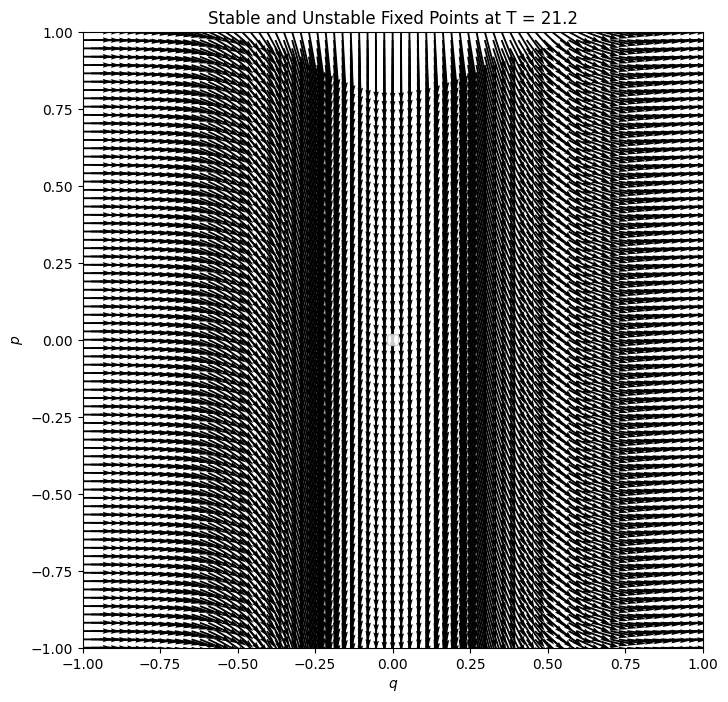

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


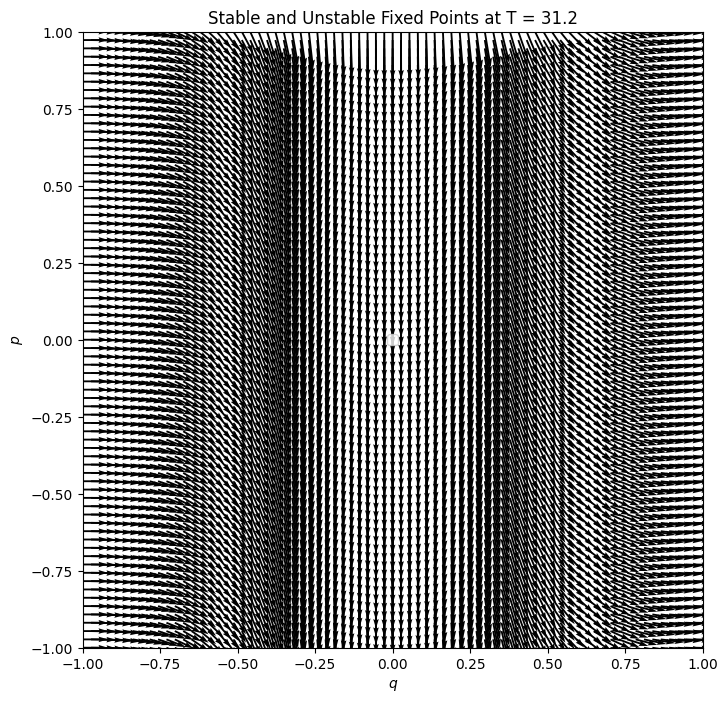

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


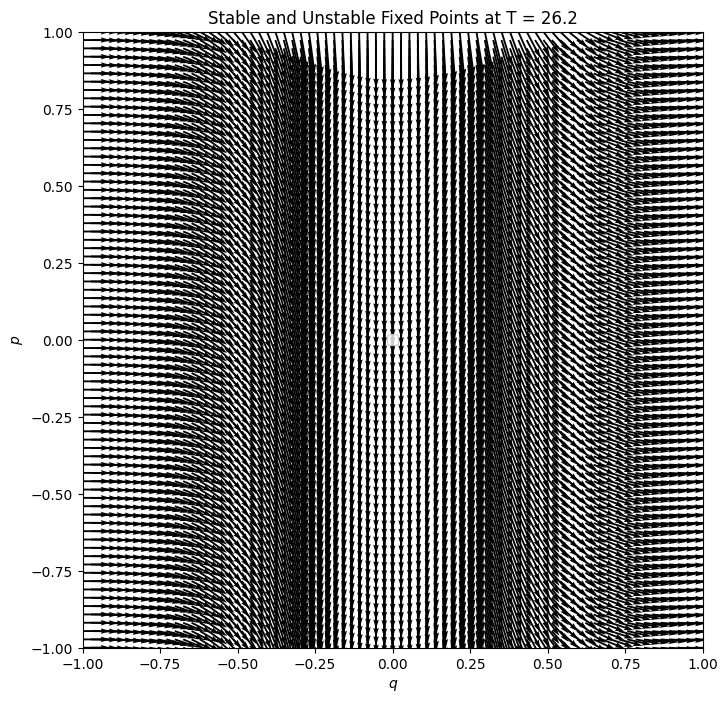

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def vector_field(q, T, N):
    beta = 1 / T
    p = np.tanh(beta * (N - 2) * q)
    dq = (np.exp(-beta * (N - 3) * (-2 * q)) - 2 * np.exp(-beta * (2 * p)) + np.exp(-beta * (N - 3) * (2 * q))) / \
         (np.exp(-beta * (N - 3) * (-2 * q)) + 2 * np.exp(-beta * (2 * p)) + np.exp(-beta * (N - 3) * (2 * q)))
    dp = -beta * (N - 2) * (1 - q**2) * (1 - p**2)
    return dq, dp

def plot_vector_field(T, N):
    
    q_range = np.linspace(-1, 1, 75)
    p_range = np.linspace(-1, 1, 75)

    
    Q, P = np.meshgrid(q_range, p_range)
    dQ, dP = vector_field(Q, T, N)

    
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.quiver(Q, P, dQ, dP, scale=20, width=0.003)

    
    for q0 in q_range:
        for p0 in p_range:
            dq_dt, dp_dt = vector_field(q0, T, N)
            if dq_dt == 0 and dp_dt == 0:
                if is_stable(q0, p0, T, N):
                    ax.plot(q0, p0, 'bo', markersize=10, label='Stable fixed point')
                else:
                    ax.plot(q0, p0, 'ro', markersize=10, label='Unstable fixed point')

    
    ax.set_xlim([-1, 1])
    ax.set_ylim([-1, 1])
    ax.set_xlabel(r'$q$')
    ax.set_ylabel(r'$p$')
    ax.set_title(f'Stable and Unstable Fixed Points at T = {T}')
    ax.legend()
    plt.show()

def is_stable(q0, p0, T, N):
    beta = 1 / T
    p0 = np.tanh(beta * (N - 2) * q0)

    
    dq_dq = (beta * (N - 3) * (np.exp(-beta * (N - 3) * (-2 * q0)) + np.exp(-beta * (N - 3) * (2 * q0)))) / \
            (np.exp(-beta * (N - 3) * (-2 * q0)) + 2 * np.exp(-beta * (2 * p0)) + np.exp(-beta * (N - 3) * (2 * q0)))
    dq_dp = (-4 * np.exp(-beta * (2 * p0))) / \
            (np.exp(-beta * (N - 3) * (-2 * q0)) + 2 * np.exp(-beta * (2 * p0)) + np.exp(-beta * (N - 3) * (2 * q0)))
    dp_dq = -beta * (N - 2) * (2 * q0 * (1 - p0**2))
    dp_dp = -beta * (N - 2) * (-2 * p0 * (1 - q0**2))

    J = np.array([[dq_dq, dq_dp], [dp_dq, dp_dp]])

    
    eigenvalues = np.linalg.eigvals(J)

    
    is_stable = np.all(np.real(eigenvalues) < 0)

    return is_stable


T_c = 26.2
N = 50


for T in [21.2, 31.2, 26.2]:
    plot_vector_field(T, N)

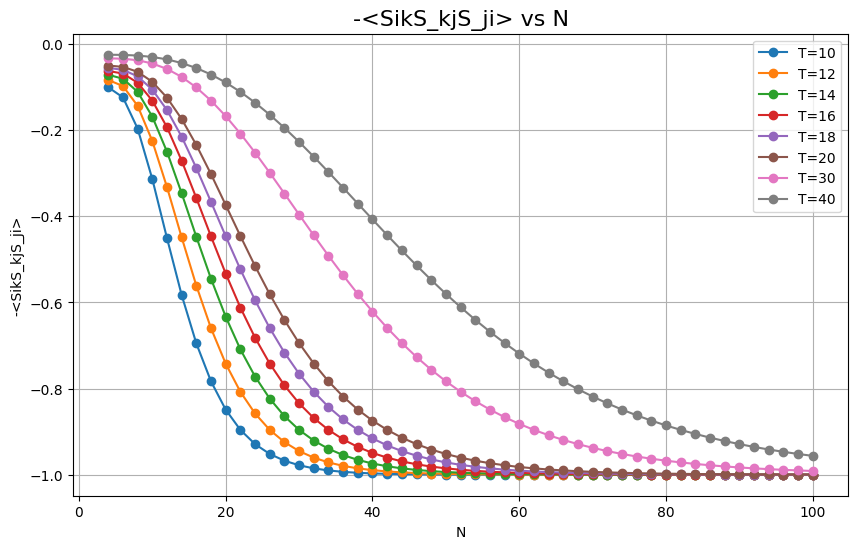

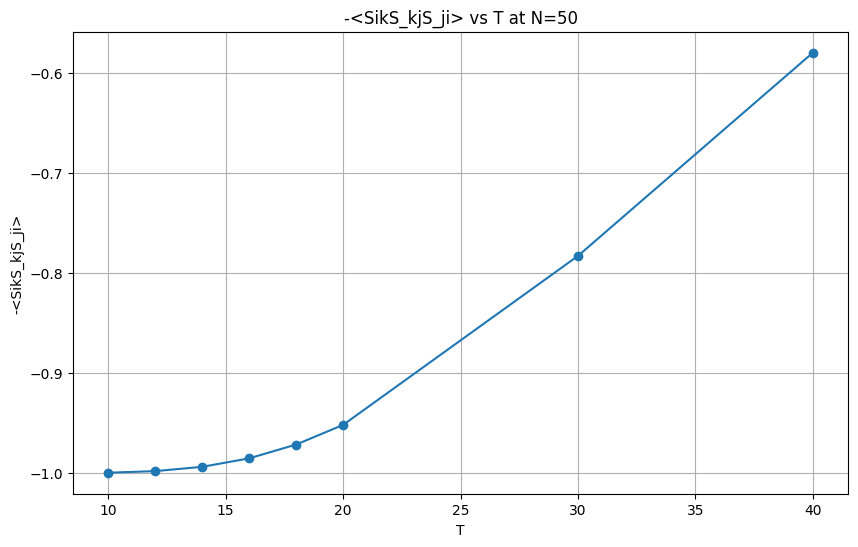

In [6]:
import numpy as np
import matplotlib.pyplot as plt


def calculate_SikS_kjS_ji(N, T):
    beta = 1 / T
    q = 1  
    numerator = (
        np.exp(beta * (N - 3) * (3 * q) + beta) -
        3 * np.exp(beta * (N - 3) * (q) - beta) +
        3 * np.exp(beta * (N - 3) * (-q) + beta) -
        np.exp(beta * (N - 3) * (-3 * q) - beta)
    )
   
    denominator = (
        np.exp(beta * (N - 3) * (3 * q) + beta) +
        3 * np.exp(beta * (N - 3) * (q) - beta) +
        3 * np.exp(beta * (N - 3) * (-q) + beta) +
        np.exp(beta * (N - 3) * (-3 * q) - beta)
    )
   
    SikS_kjS_ji = - numerator / denominator
    return SikS_kjS_ji


def plot_SikS_kjS_ji_vs_N(N_values, T_values):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.set_title('-<SikS_kjS_ji> vs N', fontsize=16)
    ax.set_xlabel('N')
    ax.set_ylabel('-<SikS_kjS_ji>')

    for T in T_values:
        results = [calculate_SikS_kjS_ji(N, T) for N in N_values]
        ax.plot(N_values, results, marker='o', label=f'T={T}')
    
    ax.legend()
    ax.grid(True)
    plt.show()


def plot_SikS_kjS_ji_vs_T(T_values, N):
    results = [calculate_SikS_kjS_ji(N, T) for T in T_values]
   
    plt.figure(figsize=(10, 6))
    plt.plot(T_values, results, marker='o')
    plt.xlabel('T')
    plt.ylabel('-<SikS_kjS_ji>')
    plt.title(f'-<SikS_kjS_ji> vs T at N={N}')
    plt.grid(True)
    plt.show()


N_values = range(4, 101, 2)  
T_values = [10, 12, 14, 16, 18, 20,30,40]  
fixed_N = 50  


plot_SikS_kjS_ji_vs_N(N_values, T_values)
plot_SikS_kjS_ji_vs_T(T_values, fixed_N)